In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Understanding the Dataset

In [3]:
df = pd.read_csv("../data/Churn_Modelling.csv")

In [4]:
# Getting to know about the data
print(f"Shape of the dataset : {df.shape}")
df.head()

Shape of the dataset : (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [5]:
# Checking the datatypes 
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [6]:
# check for duplicate in the dataset
df.duplicated().sum()

np.int64(0)

In [7]:
# Number of customer exited from bank 1-->exit
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [8]:
# Number of customers from different counties
df['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [9]:
# Number of Bank's active members 1-> active 
df['IsActiveMember'].value_counts() 

IsActiveMember
1    5151
0    4849
Name: count, dtype: int64

In [10]:
# Dropping the least important columns 
df.drop(columns=['RowNumber', 'CustomerId',	'Surname'], inplace=True) # for permanent change
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [11]:
# Performing one-hot encoding for Geography and gender as model can only be trained on numbers 
df = pd.get_dummies(df, columns=['Geography', 'Gender'], drop_first=True)
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False


## 2. Data Splitting & Normalization

In [12]:
from sklearn.model_selection import train_test_split

# Feature matrix
X = df.drop(columns=['Exited'])

# Target vector 
y = df['Exited']

# Splitting the data into training and testing 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)


print(f"Shape of X_train : {X_train.shape}")
print(f"Shape of y_train : {y_train.shape}")

Shape of X_train : (8000, 11)
Shape of y_train : (8000,)


In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


## 3. ANN implementation from scratch

In [14]:
def init_parameters(dims, seed=42):
    rng = np.random.RandomState(seed)
    parameters = {}
    
    # Xavier normal initialization to keep weights at a reasonable scale. 
    for l in range(1, len(dims)):
        fan_in = dims[l-1]
        fan_out = dims[l]
        
        scaler = np.sqrt(2 / (fan_in + fan_out))
        
        # Mean = 0, Standard Deviation = scaler and shape =  (fan_in, fan_out)
        parameters[f"W{l}"] = rng.normal(0, scaler, (fan_in, fan_out))
        parameters[f"b{l}"] = np.zeros((1, fan_out))
    
    return parameters

In [15]:
p = init_parameters([11,8,6,3,2,1])
print("Shape of b1 :", p['b1'].T.shape)
p

Shape of b1 : (8, 1)


{'W1': array([[ 0.16115535, -0.04485886,  0.21013791,  0.49413614, -0.07596939,
         -0.07596406,  0.51236429,  0.2489887 ],
        [-0.1523176 ,  0.17602972, -0.15035255, -0.15110268,  0.07850293,
         -0.62075008, -0.55963724, -0.18243016],
        [-0.32860581,  0.1019553 , -0.29460191, -0.45821183,  0.47551925,
         -0.0732515 ,  0.02190904, -0.46224935],
        [-0.17662108,  0.03598804, -0.37343163,  0.12189253, -0.19487292,
         -0.09463795, -0.1952194 ,  0.6009584 ],
        [-0.00437908, -0.34316674,  0.26686881, -0.39609398,  0.0677643 ,
         -0.63580094, -0.43092046,  0.06387022],
        [ 0.2395902 ,  0.05559921, -0.03752126, -0.09769094, -0.47969588,
         -0.2335483 , -0.14945095,  0.34297574],
        [ 0.11148449, -0.57200576,  0.10514672, -0.12493719, -0.2196225 ,
          0.19845399,  0.33450042,  0.30214717],
        [-0.27227812, -0.10032174,  0.10747605,  0.31650863, -0.15546465,
         -0.06023573, -0.35894246, -0.38810068],
        [ 

In [16]:

def sigmoid_grad(z):
    grad = output_sigmoid(z)
    return  grad * (1 - grad)

In [17]:
# Activation Function - ReLU
def activation_relu(z):
    return np.maximum(0, z)

def relu_grad(z):
    return (z > 0).astype(int)

def output_sigmoid(z):
    return 1 / (1 + np.exp(-z))


In [18]:
def linear_forward(A, W, b):
    Z = np.dot(A, W) + b
    return Z

In [19]:
# Forward Propagation
def forward_propagation(X, params):
    
    # Number of layers in the network
    layers = len(params) // 2
    
    A = np.atleast_2d(X)
    cache = {"A0":A}
    
    for l in range(1, layers + 1):
        A_prev = A
        W = params[f"W{l}"]
        b = params[f"b{l}"]
        
        Z = linear_forward(A_prev, W, b)
        
        if l == layers:
            A = output_sigmoid(Z) # Output : Sigmoid Function for binary classification
        else:
            A = activation_relu(Z) # Activation function for hidden layers - ReLU (Rectified Linear Unit)
        
        cache[f"A{l}"], cache[f"Z{l}"] = A, Z
        
    return A, cache
        
    

In [20]:
y_hat, cache= forward_propagation(X_train_scaled[3: 4], p)
y_hat

array([[0.51265869]])

In [21]:
cache

{'A0': array([[-0.50992698, -1.80142451,  1.36954838,  0.72818469,  0.81118618,
          0.64920267, -1.03615311, -0.23677491, -0.58408625,  1.75013603,
         -1.0862028 ]]),
 'A1': array([[0.        , 0.75134465, 0.        , 0.        , 0.680405  ,
         0.25828996, 0.        , 0.        ]]),
 'Z1': array([[-0.38240289,  0.75134465, -2.44870026, -0.38960686,  0.680405  ,
          0.25828996, -0.41243958, -1.47639981]]),
 'A2': array([[0.01570527, 0.29126505, 0.11184749, 0.06290506, 0.12947233,
         0.        ]]),
 'Z2': array([[ 0.01570527,  0.29126505,  0.11184749,  0.06290506,  0.12947233,
         -0.504021  ]]),
 'A3': array([[0.        , 0.0200275 , 0.17533289]]),
 'Z3': array([[-0.20451617,  0.0200275 ,  0.17533289]]),
 'A4': array([[0.       , 0.0788072]]),
 'Z4': array([[-0.10847112,  0.0788072 ]]),
 'A5': array([[0.51265869]]),
 'Z5': array([[0.0506456]])}

In [31]:
def backward_propagation(params, cache, y):
    
    # Change the shape of target 
    y = np.asarray(y).reshape(-1,1)
    
    # Number of layers in the network
    L = len(params) // 2
    
    # Prediction
    y_hat = cache[f"A{L}"]
    
    # Loss Calculation for binary classification 
    esp = 1e-12 # Small value to avoid log(0)
    y_hat_safe = np.clip(y_hat, esp, 1-esp)
    
    loss = - np.mean(
        y* np.log(y_hat_safe) + (1-y)*np.log(1-y_hat_safe) # Binary Cross Entropy Loss
    )
    
    # Gradient Accumulator for all layers
    grads = {}
    
    # Gradient of output layer (L)
    dz = (y_hat - y)
    
    for l in range(L, 0, -1):
        grads[f"W{l}"] = np.dot(cache[f"A{l-1}"].T, dz)
        grads[f"b{l}"] = np.sum(dz, axis=0, keepdims=True)
        
        if l > 1:
            dz = np.dot(dz, params[f"W{l}"].T) * relu_grad(cache[f"Z{l-1}"])
    
    return grads, loss
        

In [23]:
g=backward_propagation(p, cache, y[3: 4])

In [24]:
def update_parameters(params, grads, learning_rate=0.01):
    
    for l in range(1, 1+(len(params)//2) ):
        params[f"W{l}"] -= learning_rate * grads[f"W{l}"]
        params[f"b{l}"] -= learning_rate * grads[f"b{l}"]
        
    return params

In [25]:
update_parameters(p, g)

{'W1': array([[ 0.16115535, -0.04521187,  0.21013791,  0.49413614, -0.07560892,
         -0.07537414,  0.51236429,  0.2489887 ],
        [-0.1523176 ,  0.17478264, -0.15035255, -0.15110268,  0.07977634,
         -0.61866608, -0.55963724, -0.18243016],
        [-0.32860581,  0.10290341, -0.29460191, -0.45821183,  0.47455113,
         -0.07483588,  0.02190904, -0.46224935],
        [-0.17662108,  0.03649215, -0.37343163,  0.12189253, -0.19538767,
         -0.09548036, -0.1952194 ,  0.6009584 ],
        [-0.00437908, -0.34260517,  0.26686881, -0.39609398,  0.06719088,
         -0.63673938, -0.43092046,  0.06387022],
        [ 0.2395902 ,  0.05604864, -0.03752126, -0.09769094, -0.48015479,
         -0.23429934, -0.14945095,  0.34297574],
        [ 0.11148449, -0.57272306,  0.10514672, -0.12493719, -0.21889005,
          0.19965268,  0.33450042,  0.30214717],
        [-0.27227812, -0.10048566,  0.10747605,  0.31650863, -0.15529728,
         -0.05996181, -0.35894246, -0.38810068],
        [ 

In [51]:
# Training Loop 
# [11,8,6,3,2,1]
parameters = init_parameters([11,10,5,2,1])

epochs = 100
lr = 0.001

y_train_array = y_train.to_numpy(dtype=float).reshape(-1, 1)
y_test_array = y_test.to_numpy(dtype=float).reshape(-1, 1)

train_acc_per_epoch = []
test_acc_per_epoch = []
train_loss_per_epoch = []
test_loss_per_epoch = []


for epoch in range(epochs):
    
    for i in range(X_train_scaled.shape[0]):
        
        x = X_train_scaled[i:i+1]
        y_true = y_train[i:i+1]
        
        # Forward Pass
        _ , cache = forward_propagation(x, parameters)
        
        # Backward Pass
        grads, _ = backward_propagation(parameters, cache, y_true)
        
        # Update the parameters
        parameters = update_parameters(parameters, grads, lr)
    
    # For Training data
    train_probs, _ = forward_propagation(X_train_scaled, parameters)
    test_probs, _ = forward_propagation(X_test_scaled, parameters)
    
    # Training and test loss.              min.    max
    train_prob_safe = np.clip(train_probs, 1e-12, 1 - 1e-12)
    test_prob_safe = np.clip(test_probs, 1e-12, 1 - 1e-12)
    
    # Binary cross entropy loss
    
    train_loss = - np.mean(
        y_train_array * np.log(train_prob_safe) + (1 - y_train_array) * np.log(1 - train_prob_safe)
    )
    
    test_loss = - np.mean(
        y_test_array * np.log(test_prob_safe) + (1 - y_test_array) * np.log(1 - test_prob_safe)
    )
    
    # Condition 
    train_pred = (train_probs >= 0.5).astype(int)
    test_pred = (test_probs >= 0.5).astype(int)
    
    # Accuracy
    train_acc = np.mean(train_pred == y_train_array) 
    test_acc = np.mean(test_pred == y_test_array) 
    
    train_acc_per_epoch.append(train_acc)
    test_acc_per_epoch.append(test_acc)
    train_loss_per_epoch.append(train_loss)
    test_loss_per_epoch.append(test_loss)
    
    if epoch % 10 ==0:
        print(
            f"Epoch {epoch+1} | Train Acc: {train_acc:.2%} | Test Acc: {test_acc:.2%}")


Epoch 1 | Train Acc: 79.33% | Test Acc: 80.85%
Epoch 11 | Train Acc: 85.08% | Test Acc: 84.70%
Epoch 21 | Train Acc: 86.15% | Test Acc: 85.65%
Epoch 31 | Train Acc: 86.26% | Test Acc: 86.00%
Epoch 41 | Train Acc: 86.25% | Test Acc: 85.90%
Epoch 51 | Train Acc: 86.24% | Test Acc: 86.05%
Epoch 61 | Train Acc: 86.34% | Test Acc: 85.90%
Epoch 71 | Train Acc: 86.39% | Test Acc: 86.10%
Epoch 81 | Train Acc: 86.45% | Test Acc: 85.90%
Epoch 91 | Train Acc: 86.51% | Test Acc: 85.95%


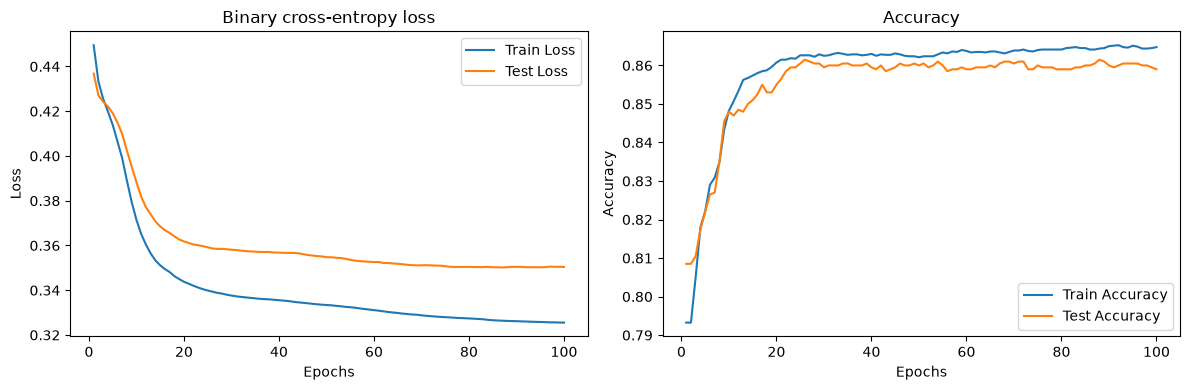

In [52]:
total_epochs = range(1, epochs + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(total_epochs, train_loss_per_epoch , label="Train Loss")
axes[0].plot(total_epochs, test_loss_per_epoch , label="Test Loss")
axes[0].set(title="Binary cross-entropy loss", xlabel="Epochs", ylabel="Loss")
axes[0].legend()


axes[1].plot(total_epochs, train_acc_per_epoch , label="Train Accuracy") 
axes[1].plot(total_epochs, test_acc_per_epoch , label="Test Accuracy")
axes[1].set(title="Accuracy", xlabel="Epochs", ylabel="Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()